**ANOMALY DETECTION OC-SVM**

In [1]:
import digitalhub as dh
import zipfile
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


**SETUP PARAMETERS**

In [ ]:
job_name = "net_v3_30per"
dataset_standard = "Standard"
dataset_anomalies = "Floods_Anomalies_v3_crop_norm"
moco_version = "net_v3"

parameters = {
    "job_name": job_name,                           # nome di QUESTO job (i risultati escono come anomaly_results_{job_name})
    "dataset_standard": dataset_standard,
    "dataset_anomalies": dataset_anomalies,         # artifact con SAR/ e OPT/ (partNN.zip di .npy)
    "moco_version": moco_version,                   # versione del TRAINING MoCo da valutare
    "simple_proj": False,                           # questi 6 devono essere identici a quelli del training,
    "attn": False,                                  # altrimenti load_state_dict fallisce per shape diverse
    "hidden_channels_dim": 64,
    "pool_grid": 4,

    "moco_dim": 128,
    "moco_k": 4096,
    "moco_m": 0.999,
    "moco_t": 0.07,
    "patch_size": 256,
    "n_images1": 4, "n_channels1": 2,       # sar
    "n_images2": 4, "n_channels2": 10,      # ottico
    "standardize": True,                    # StandardScaler sul vettore concatenato [q; k]
    "batch_size": 16,
    "workers": 0,
    "min_flood_area": 30.0,
}

volumes = [
    {
        "volume_type": "ephemeral",
        "name": "volume-spazio-dati",
        "mount_path": "/data",
        "spec": {"size": "500Gi"}
    }
]

**BUILD ENVIRONMENT**

In [ ]:
ad_ocsvm_func = project.new_function(
    name=f'ad_md_{job_name}',
    kind="python",
    python_version="PYTHON3_10",
    code_src="../src/",
    handler="anomaly:ad_md",
    base_image="pytorch/pytorch:2.1.2-cuda11.8-cudnn8-runtime",
    requirements=["pandas==2.3.3", "numpy==1.26.4", "rasterio==1.4.4", "tqdm==4.70.0", "tifffile==2024.8.30", "torch==2.1.2", "matplotlib==3.10.9", "digitalhub==0.15.11", "digitalhub-runtime-python==0.15.2", "zarr==2.18.0", "numcodecs==0.13.1", "xarray==2025.6.1", "scikit-learn==1.5.2"]
)

build = ad_ocsvm_func.run("build", wait=True)
print(f"BUILD: {build.status.state}")

2026-10-12 11:30:03,545 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 9d9241ccd07343ad97ab34a38e8011b0 to finish...
2026-10-12 11:30:08,552 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 9d9241ccd07343ad97ab34a38e8011b0 to finish...
2026-10-12 11:30:13,560 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 9d9241ccd07343ad97ab34a38e8011b0 to finish...
2026-10-12 11:30:18,569 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 9d9241ccd07343ad97ab34a38e8011b0 to finish...
2026-10-12 11:30:23,579 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 9d9241ccd07343ad97ab34a38e8011b0 to finish...
2026-10-12 11:30:28,588 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 9d9241ccd07343ad97ab34a38e8011b0 to finish...
2026-10-12 11:30:33,596 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 9d9241ccd07343ad97ab34a38e8011b0 to finish...
2026-10-12 11

BUILD: COMPLETED


**TRAINING**

In [ ]:
run_ad = ad_ocsvm_func.run(
    action="job",
    parameters=parameters,
    volumes=volumes,
    profile="1xv100-shared",
    local_execution=False,
    wait=True
)

print(f"Run anomaly detection OC-SVM avviato: {run_ad.id}")

2026-10-12 11:30:58,816 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 3723e02314d24447bb98cf0534ffa716 to finish...


2026-10-12 11:31:03,823 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 3723e02314d24447bb98cf0534ffa716 to finish...
2026-10-12 11:31:08,832 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 3723e02314d24447bb98cf0534ffa716 to finish...
2026-10-12 11:31:13,841 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 3723e02314d24447bb98cf0534ffa716 to finish...
2026-10-12 11:31:18,953 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 3723e02314d24447bb98cf0534ffa716 to finish...
2026-10-12 11:31:23,962 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 3723e02314d24447bb98cf0534ffa716 to finish...
2026-10-12 11:31:28,971 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 3723e02314d24447bb98cf0534ffa716 to finish...
2026-10-12 11:31:33,979 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 3723e02314d24447bb98cf0534ffa716 to finish...
2026-10-12 11

In [ ]:
RESULTS_DIR = "/tmp/anomaly_results_pca"

zip_path = project.get_artifact(f"anomaly_results_pca_{job_name}").download("/tmp/anomaly_results_pca.zip", overwrite=True)
with zipfile.ZipFile(zip_path) as z:
    z.extractall(RESULTS_DIR)
with open(f"{RESULTS_DIR}/anomaly_results.json") as f:
    results = json.load(f)

df = pd.read_csv(f"{RESULTS_DIR}/scores.csv")                    # le statistiche dei punteggi si calcolano da qui (nel json della PCA non ci sono)
score_normal = df[df.label == 0]['score']
score_anom = df[df.label == 1]['score']

print(f"n_fit: {results['n_fit']} | n_normali: {results['n_normali']} | n_anomale: {results['n_anomale']}", "\n")
print(f"PCA: k={results['k']} | varianza spiegata={results['varianza_spiegata']:.3f} | min_flood_area={results['min_flood_area']:.3f} | standardize={results['standardize']}")
print(f"score normali: {score_normal.mean():.4f} ± {score_normal.std():.4f}")
print(f"score anomale: {score_anom.mean():.4f} ± {score_anom.std():.4f}", "\n")
print(f"AUROC (score basso = anomalia): {results['auroc']:.3f}")

df_rules = pd.DataFrame(results['rules']).T
df_rules

n_fit: 2402 | n_normali: 815 | n_anomale: 815 

PCA: k=8 | varianza spiegata=0.291 | standardize=True
score normali: -184.2641 ± 41.2979
score anomale: -226.4370 ± 32.9236 

AUROC (score basso = anomalia): 0.791


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
pca residuo score < soglia (FA voluto 5%),-263.833368,116.0,9.0,699.0,399.0,0.022059,0.857669,0.142331,0.928000,0.246809
pca residuo score < soglia (FA voluto 10%),-242.638678,245.0,24.0,570.0,384.0,0.058824,0.699387,0.300613,0.910781,0.452030
pca residuo score < soglia (FA voluto 15%),-231.878085,349.0,42.0,466.0,366.0,0.102941,0.571779,0.428221,0.892583,0.578773
pca residuo score < soglia (FA voluto 20%),-223.937668,417.0,60.0,398.0,348.0,0.147059,0.488344,0.511656,0.874214,0.645511
pca residuo score < soglia (FA voluto 25%),-217.018425,492.0,75.0,323.0,333.0,0.183824,0.396319,0.603681,0.867725,0.712012
pca residuo score < soglia (FA voluto 30%),-208.254681,596.0,103.0,219.0,305.0,0.252451,0.268712,0.731288,0.852647,0.787318


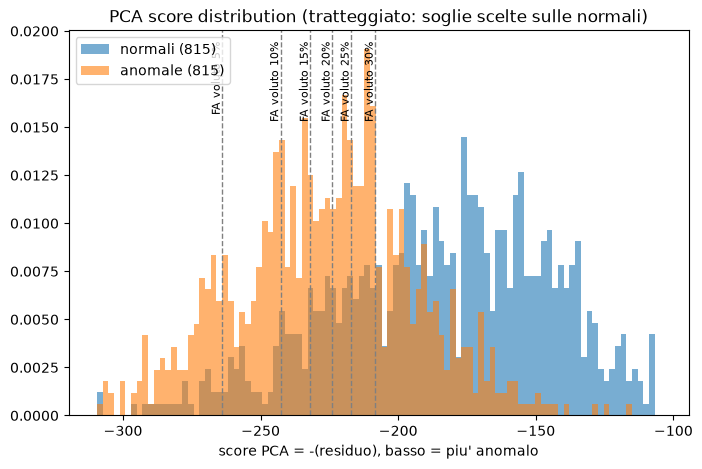

In [ ]:
df = pd.read_csv(f"{RESULTS_DIR}/scores.csv")
score_normal = df[df.label == 0]['score']
score_anom = df[df.label == 1]['score']

lo, hi = np.quantile(df.score, [0.005, 0.995])                   # si taglia lo 0.5% piu' estremo per lato: le code lunghe schiacciano il grafico
bins = np.linspace(lo, hi, 100)

plt.figure(figsize=(8, 5))
plt.hist(score_normal, bins=bins, alpha=0.6, density=True, label=f"normali ({len(score_normal)})")
plt.hist(score_anom, bins=bins, alpha=0.6, density=True, label=f"anomale ({len(score_anom)})")
for nome, r in results['rules'].items():                         # una riga tratteggiata per ogni soglia salvata nel json
    if lo <= r["soglia"] <= hi:
        plt.axvline(x=r["soglia"], color='gray', linestyle='--', linewidth=1)
        plt.text(r["soglia"], plt.ylim()[1] * 0.97, nome.split("(")[-1].rstrip(")"), rotation=90, va="top", ha="right", fontsize=8)   # scritta: "FA voluto 5%"
plt.xlabel("score PCA = -(residuo), basso = piu' anomalo")
plt.legend(loc="upper left")
plt.title("PCA score distribution (tratteggiato: soglie scelte sulle normali)")
plt.show()

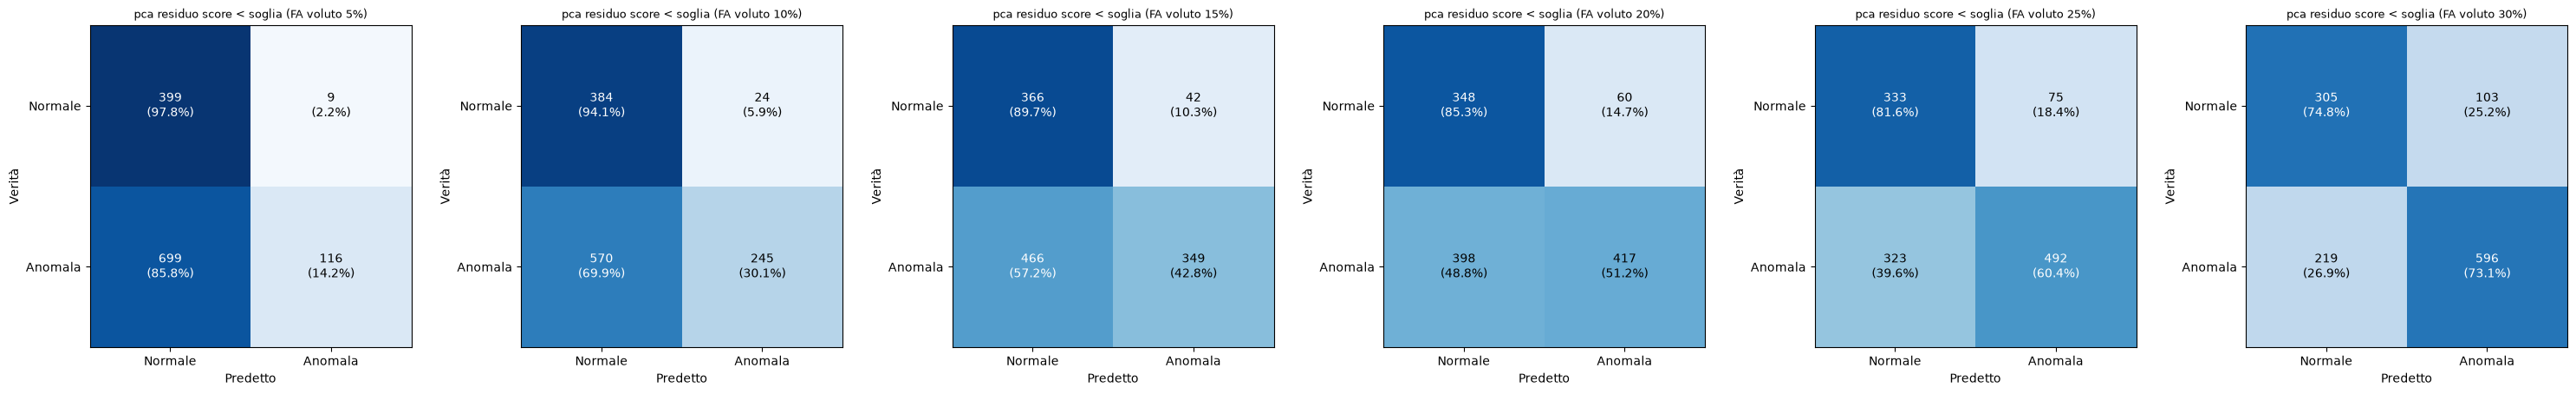

In [ ]:
rules = results['rules']
fig, axes = plt.subplots(1, len(rules), figsize=(5 * len(rules), 4.5), squeeze=False)

for ax, (nome, r) in zip(axes[0], rules.items()):
    mat = np.array([[r["TN"], r["FP"]],
                     [r["FN"], r["TP"]]])
    mat_pct = mat / mat.sum(axis=1, keepdims=True) * 100

    im = ax.imshow(mat_pct, cmap="Blues", vmin=0, vmax=100)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
    ax.set_xlabel("Predetto"); ax.set_ylabel("Verità")
    ax.set_title(nome, fontsize=9)

    for i in range(2):
        for j in range(2):
            color = "white" if mat_pct[i, j] > 55 else "black"
            ax.text(j, i, f"{int(mat[i, j])}\n({mat_pct[i, j]:.1f}%)",
                    ha="center", va="center", color=color, fontsize=10)

plt.tight_layout()
plt.show()